In [67]:
import igraph as ig
import leidenalg as la
import cairo
import os
import palettable

net_graph_all_pos = ig.Graph()
output_dir = "/Users/htang/Documents/PhD/Project - CAS/C3_Microbiome/2019-10-24_QIIME_CAS_COAST_meta_5/" + \
    "output/2020-09-25_fastspar_community/"
net_graph_all_pos_gml = net_graph_all_pos.Read_GML(output_dir + "net.graph.all.pos.txt")
ig.summary(net_graph_all_pos_gml)

IGRAPH UNW- 532 23274 -- 
+ attr: id (v), name (v), weight (e)


In [68]:
net_graph_all_pos_layout = net_graph_all_pos_gml.layout_fruchterman_reingold()
color_tuple = tuple(palettable.colorbrewer.qualitative.Set3_12.colors[1])
color_tuple2 = tuple(x/255 for x in tuple(palettable.colorbrewer.qualitative.Set3_12.colors[1]))
color_tuple2

(1.0, 1.0, 0.7019607843137254)

In [69]:
# load consensus clustering packages
from urllib.request import urlopen
import numpy as np
import matplotlib.pyplot as plt
import bct
from netneurotools import plotting
from netneurotools import cluster

(532, 532)


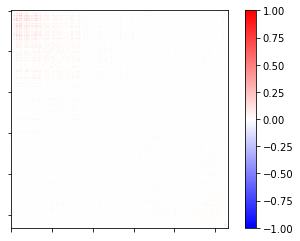

In [70]:
# Read adjacency matrix as array
import csv
# with open(output_dir + 'net.graph.all.pos.adj.txt', \
#           newline='') as csvfile:
#     net_graph_all_pos_adj = list(csv.reader(csvfile, delimiter = "\t"))

corr = np.genfromtxt(output_dir + 'net.graph.all.pos.adj.txt', \
                                   delimiter=" ", dtype=None, encoding=None)
print(corr.shape)

fig, ax = plt.subplots(1, 1)
coll = ax.imshow(corr, vmin=-1, vmax=1, cmap='bwr')
ax.set(xticklabels=[], yticklabels=[])
fig.colorbar(coll)

In [73]:
# Seed 1
# Resolution limit 1
x = 1
res_para = 1

# Get partitions, Leiden RBCVP
# Note that this is the same as ModularityVertexPartition 
# when setting 𝛾=1 and normalising by 2𝑚, or 𝑚 for directed graphs.
net_graph_all_pos_part = la.find_partition(net_graph_all_pos_gml, \
                                                   la.RBConfigurationVertexPartition, \
                                                   seed = x, resolution_parameter = res_para)
# Get number of partitions
net_graph_all_pos_part_num = len(set(net_graph_all_pos_part.membership))
print('{} clusters detected.'\
      .format(net_graph_all_pos_part_num))

ci = np.array(net_graph_all_pos_part.membership)
ci

4 clusters detected.


array([0, 0, 1, 0, 0, 2, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 2, 0, 1, 2, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 3, 1, 2, 1, 1, 1,
       1, 1, 2, 1, 1, 1, 1, 2, 1, 1, 0, 2, 2, 1, 1, 2, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 2, 1, 1, 2, 1, 0, 2, 0, 0, 1, 1, 0, 0, 1, 1, 2, 0, 1, 1,
       1, 1, 1, 1, 0, 1, 2, 1, 2, 0, 2, 2, 1, 0, 1, 1, 1, 2, 1, 0, 2, 1,
       0, 2, 1, 1, 0, 2, 1, 1, 2, 0, 1, 1, 1, 0, 0, 2, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 1, 1, 2, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0,
       0, 1, 2, 0, 2, 0, 0, 0, 1, 0, 1, 0, 0, 3, 0, 0, 1, 2, 0, 2, 1, 1,
       0, 0, 0, 1, 0, 2, 1, 0, 0, 0, 2, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 3,
       0, 0, 2, 2, 0, 1, 0, 1, 0, 1, 0, 0, 1, 2, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 2, 0, 0, 1, 1,
       1, 0, 0, 1, 1, 0, 0, 0, 2, 1, 0, 1, 2, 2, 0,

<AxesSubplot:>

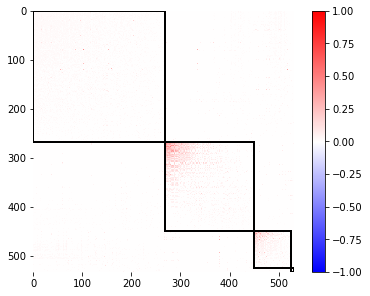

In [74]:
plotting.plot_mod_heatmap(corr, ci, vmin=-1, vmax=1, cmap='bwr')

array([3, 3, 1, 3, 0, 3, 0, 1, 1, 3, 3, 3, 1, 1, 1, 1, 3, 0, 1, 1, 1, 1,
       1, 3, 1, 1, 3, 3, 3, 3, 3, 0, 1, 1, 1, 3, 3, 1, 1, 1, 1, 3, 1, 1,
       3, 1, 1, 1, 3, 1, 1, 1, 1, 2, 3, 1, 2, 1, 0, 1, 1, 1, 1, 1, 1, 3,
       1, 1, 2, 1, 2, 1, 1, 1, 1, 3, 3, 1, 3, 2, 1, 1, 1, 1, 2, 1, 1, 1,
       3, 1, 2, 1, 1, 1, 1, 2, 3, 3, 0, 2, 2, 3, 1, 2, 1, 1, 1, 1, 3, 3,
       1, 0, 1, 2, 1, 1, 2, 1, 0, 2, 0, 0, 1, 1, 0, 0, 1, 1, 2, 0, 1, 1,
       1, 3, 1, 3, 0, 1, 2, 1, 2, 0, 2, 2, 1, 0, 1, 1, 1, 2, 1, 0, 2, 1,
       0, 2, 1, 1, 0, 2, 1, 1, 1, 0, 1, 1, 1, 0, 0, 2, 1, 0, 3, 0, 0, 1,
       0, 0, 3, 1, 1, 2, 3, 0, 0, 0, 3, 1, 0, 1, 1, 0, 3, 0, 0, 0, 1, 0,
       0, 3, 2, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 2, 0, 2, 1, 1,
       0, 0, 0, 1, 0, 1, 1, 0, 0, 3, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 3, 1,
       0, 0, 2, 2, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 1, 3, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 1, 0, 2, 0, 0, 1, 1,
       1, 0, 0, 1, 3, 3, 0, 0, 2, 1, 0, 1, 2, 2, 0,

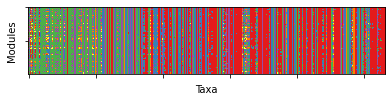

In [83]:
# Repeat Leiden 100 times 
ci = [np.array(la.find_partition(net_graph_all_pos_gml, \
                        la.RBConfigurationVertexPartition, \
                        seed = x, resolution_parameter = res_para).membership) \
      for x in range(100)]

# Create plot of modules ~ ROIs
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(ci, cmap='Set1')
ax.set(ylabel='Modules', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])

ci[0]

<AxesSubplot:>

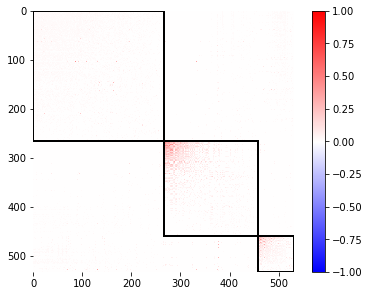

In [81]:
consensus = cluster.find_consensus(np.column_stack(ci), seed=1)
plotting.plot_mod_heatmap(corr, consensus, vmin=-1, vmax=1, cmap='bwr')

In [82]:
consensus

array([1, 2, 2, 1, 1, 3, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 1, 2, 3, 2, 1, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 3, 2, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 3, 2, 2, 2,
       2, 2, 3, 2, 2, 2, 2, 3, 2, 2, 1, 3, 3, 2, 2, 3, 2, 2, 2, 2, 2, 2,
       2, 1, 2, 3, 2, 2, 3, 2, 1, 3, 1, 1, 2, 2, 1, 1, 2, 2, 3, 1, 2, 2,
       2, 2, 2, 2, 1, 2, 3, 2, 3, 1, 3, 3, 2, 1, 2, 2, 2, 3, 2, 1, 3, 2,
       1, 3, 2, 2, 1, 3, 2, 2, 3, 1, 2, 2, 2, 1, 1, 3, 2, 1, 2, 1, 1, 2,
       1, 1, 2, 2, 2, 3, 2, 1, 1, 1, 2, 2, 1, 2, 2, 1, 2, 1, 1, 1, 2, 1,
       1, 2, 3, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 2, 3, 1, 3, 2, 2,
       1, 1, 1, 2, 1, 2, 2, 1, 1, 1, 3, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2,
       1, 1, 3, 3, 1, 2, 1, 2, 1, 2, 1, 1, 2, 3, 1, 2, 1, 1, 1, 1, 1, 2,
       1, 2, 1, 2, 2, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 3, 1, 1, 2, 2,
       2, 1, 1, 2, 2, 1, 1, 1, 3, 2, 1, 2, 3, 3, 1,